# Option Pricing Engine

This notebook prices European and American options using three independent methods: **Black-Scholes**, a **Cox-Ross-Rubinstein binomial tree**, and **Monte Carlo simulation**. It cross-validates the methods against each other, extends Monte Carlo to a path-dependent option (an arithmetic Asian) that has no closed-form price, and then points the engine at **live market data**: it pulls a real option chain, backs out implied volatilities, plots the volatility smile, and compares model prices with market quotes.

### Pipeline
1. **Set up** dependencies
2. **Price** European options in closed form with Black-Scholes and compute the Greeks
3. **Price** European and American options with a binomial tree
4. **Price** options by simulating asset price paths with Monte Carlo
5. **Validate** with put-call parity, finite-difference Greeks, and convergence tests (with charts)
6. **Compare** the methods on early exercise and path dependence
7. **Summarize** accuracy vs. speed across all engines
8. **Apply** the engine to live market data: implied volatility, the volatility smile, model vs. market prices, Greeks, and P&L scenarios
9. **Hedge**: delta-hedge a short option by simulation to see what the implied-vs-realized volatility gap is worth in dollars
10. **Discuss** limitations and extensions

### Concepts demonstrated
- Risk-neutral valuation and the Black-Scholes model
- Option Greeks (delta, gamma, vega, theta, rho)
- Lattice methods and backward induction
- Monte Carlo simulation under geometric Brownian motion
- Variance reduction (antithetic variates)
- Model validation and numerical convergence
- Implied volatility and the volatility smile
- Realized vs. implied volatility (the volatility risk premium)
- Model-vs-market comparison and option P&L scenario analysis
- Delta-hedging P&L, the volatility risk premium in dollars, and discrete-hedging error

## 1. Setup — install and import dependencies
NumPy, SciPy, pandas, and matplotlib come preinstalled on Colab. `yfinance` is used in Section 8 to pull live (≈15-minute delayed) prices and option chains, so we install it once per session. `scipy.optimize.brentq` is the root-finder behind implied volatility.

In [29]:
# Run once per Colab session.
!pip install -q yfinance

In [30]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import display
from scipy.optimize import brentq
from scipy.stats import norm

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

## 2. Black-Scholes pricing and Greeks
Black-Scholes gives a closed-form price for European options on an asset with constant volatility, a constant risk-free rate, and a continuous dividend yield $q$:

$$C = S e^{-qT}N(d_1) - K e^{-rT}N(d_2), \qquad P = K e^{-rT}N(-d_2) - S e^{-qT}N(-d_1)$$

$$d_1 = \frac{\ln(S/K) + (r - q + \tfrac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

Because it is exact and fast, it serves as the **benchmark** that the binomial and Monte Carlo engines are tested against. The same cell also computes the Greeks analytically (delta, gamma, vega, theta, rho).

*Conventions:* vega is per 1.00 change in volatility (divide by 100 for per vol point), and theta is per year (divide by 365 for per day).

In [31]:
def _d1_d2(S, K, T, r, sigma, q):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return d1, d1 - sigma * np.sqrt(T)


def bs_price(S, K, T, r, sigma, q=0.0, call=True):
    d1, d2 = _d1_d2(S, K, T, r, sigma, q)
    if call:
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)


def bs_greeks(S, K, T, r, sigma, q=0.0, call=True):
    d1, d2 = _d1_d2(S, K, T, r, sigma, q)
    pdf = norm.pdf(d1)
    eq, er = np.exp(-q * T), np.exp(-r * T)
    gamma = eq * pdf / (S * sigma * np.sqrt(T))
    vega = S * eq * pdf * np.sqrt(T)  # per 1.00 change in vol
    if call:
        delta = eq * norm.cdf(d1)
        theta = (-S * eq * pdf * sigma / (2 * np.sqrt(T))
                 - r * K * er * norm.cdf(d2) + q * S * eq * norm.cdf(d1))
        rho = K * T * er * norm.cdf(d2)
    else:
        delta = -eq * norm.cdf(-d1)
        theta = (-S * eq * pdf * sigma / (2 * np.sqrt(T))
                 + r * K * er * norm.cdf(-d2) - q * S * eq * norm.cdf(-d1))
        rho = -K * T * er * norm.cdf(-d2)
    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta, "rho": rho}

## 3. Binomial tree (Cox-Ross-Rubinstein)
The tree discretizes the asset's path into `steps` periods. Each period the price moves up by a factor $u = e^{\sigma\sqrt{\Delta t}}$ or down by $d = 1/u$, with risk-neutral probability

$$p = \frac{e^{(r-q)\Delta t} - d}{u - d}$$

We compute payoffs at expiry and work **backward** through the tree, discounting expected values at each node. For an **American** option, we also compare each node's continuation value to its immediate exercise value and keep the larger. This early-exercise check is what Black-Scholes cannot do.

In [32]:
def binomial_price(S, K, T, r, sigma, q=0.0, call=True, american=False, steps=500):
    dt = T / steps
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp((r - q) * dt) - d) / (u - d)
    disc = np.exp(-r * dt)

    def payoff(prices):
        return np.maximum(prices - K, 0) if call else np.maximum(K - prices, 0)

    j = np.arange(steps + 1)  # j = number of down moves
    V = payoff(S * u ** (steps - j) * d**j)

    for i in range(steps - 1, -1, -1):
        V = disc * (p * V[: i + 1] + (1 - p) * V[1 : i + 2])
        if american:
            j = np.arange(i + 1)
            V = np.maximum(V, payoff(S * u ** (i - j) * d**j))
    return V[0]

## 4. Monte Carlo simulation
Under the risk-neutral measure, the asset follows geometric Brownian motion, so the terminal price is

$$S_T = S \exp\!\left[\left(r - q - \tfrac{1}{2}\sigma^2\right)T + \sigma\sqrt{T}\,Z\right], \qquad Z \sim N(0,1)$$

The option price is the discounted average payoff across many simulated paths. Two functions are implemented:

- **`mc_price`**: European option using the terminal price directly, with **antithetic variates** (each draw $Z$ is paired with $-Z$) to reduce variance. Each pair is averaged before computing the standard error, so the confidence interval is valid.
- **`mc_asian_price`**: arithmetic-average Asian option, which requires simulating the full path (252 daily steps). It has no closed-form price, so this is where simulation is necessary.

In [33]:
def mc_price(S, K, T, r, sigma, q=0.0, call=True, n_paths=200_000, seed=None):
    """European option, antithetic variates. Returns (price, standard_error)."""
    rng = np.random.default_rng(seed)
    z = rng.standard_normal(n_paths // 2)
    drift = (r - q - 0.5 * sigma**2) * T
    vol = sigma * np.sqrt(T)

    def pay(zz):
        ST = S * np.exp(drift + vol * zz)
        return np.maximum(ST - K, 0) if call else np.maximum(K - ST, 0)

    pair = 0.5 * (pay(z) + pay(-z)) * np.exp(-r * T)
    return pair.mean(), pair.std(ddof=1) / np.sqrt(len(pair))


def mc_asian_price(S, K, T, r, sigma, q=0.0, call=True, n_paths=100_000,
                   n_steps=252, seed=None):
    """Arithmetic-average Asian option. Returns (price, standard_error)."""
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    z = rng.standard_normal((n_paths, n_steps))
    log_paths = np.cumsum((r - q - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z, axis=1)
    avg = (S * np.exp(log_paths)).mean(axis=1)
    pay = np.maximum(avg - K, 0) if call else np.maximum(K - avg, 0)
    pay *= np.exp(-r * T)
    return pay.mean(), pay.std(ddof=1) / np.sqrt(n_paths)

## 5. Validation — do the three engines agree?
We price a single test option: spot $S = 100$, strike $K = 105$, one year to expiry, risk-free rate 4%, volatility 25%, dividend yield 1%. Change these inputs and re-run the cells below to experiment.

### Baseline Black-Scholes prices

In [34]:
S, K, T, r, sigma, q = 100, 105, 1.0, 0.04, 0.25, 0.01

bs_c = bs_price(S, K, T, r, sigma, q, call=True)
bs_p = bs_price(S, K, T, r, sigma, q, call=False)
print(f"Black-Scholes   call {bs_c:.4f}   put {bs_p:.4f}")

Black-Scholes   call 9.0310   put 10.9089


### Sanity checks: put-call parity and Greeks
Two independent checks on the closed-form code:
- **Put-call parity:** $C - P = Se^{-qT} - Ke^{-rT}$ should hold to machine precision.
- **Greeks vs. finite differences:** each analytic Greek is compared with a numerical bump of the pricer, e.g. $\Delta \approx \frac{P(S+h) - P(S-h)}{2h}$. Agreement confirms the formulas were implemented correctly.

In [35]:
parity = bs_c - bs_p - (S * np.exp(-q * T) - K * np.exp(-r * T))
print(f"Put-call parity residual: {parity:.2e}")

g = bs_greeks(S, K, T, r, sigma, q, call=True)
h = 0.01
fd_delta = (bs_price(S + h, K, T, r, sigma, q) - bs_price(S - h, K, T, r, sigma, q)) / (2 * h)
fd_gamma = (bs_price(S + h, K, T, r, sigma, q) - 2 * bs_c + bs_price(S - h, K, T, r, sigma, q)) / h**2
fd_vega = (bs_price(S, K, T, r, sigma + 1e-4, q) - bs_price(S, K, T, r, sigma - 1e-4, q)) / 2e-4
print(f"Delta {g['delta']:.6f} vs FD {fd_delta:.6f}")
print(f"Gamma {g['gamma']:.6f} vs FD {fd_gamma:.6f}")
print(f"Vega  {g['vega']:.4f} vs FD {fd_vega:.4f}")

Put-call parity residual: 7.11e-15
Delta 0.514702 vs FD 0.514702
Gamma 0.015779 vs FD 0.015779
Vega  39.4482 vs FD 39.4482


### Visualizing the Greeks and option value
Greeks are easier to interpret as curves than as single numbers. The panels below show how each Greek changes with the spot price for the test option (K = 105, one year to expiry):

- **Delta** moves from 0 to 1 for a call (0 to −1 for a put): the hedge ratio, and roughly the probability of finishing in the money.
- **Gamma** and **vega** are largest around the money (gamma's peak sits somewhat below the strike for a one-year option) and are identical for calls and puts.
- **Theta** (time decay) is most negative around the money, where time value is largest. Vega is shown per 1 volatility point and theta per calendar day.

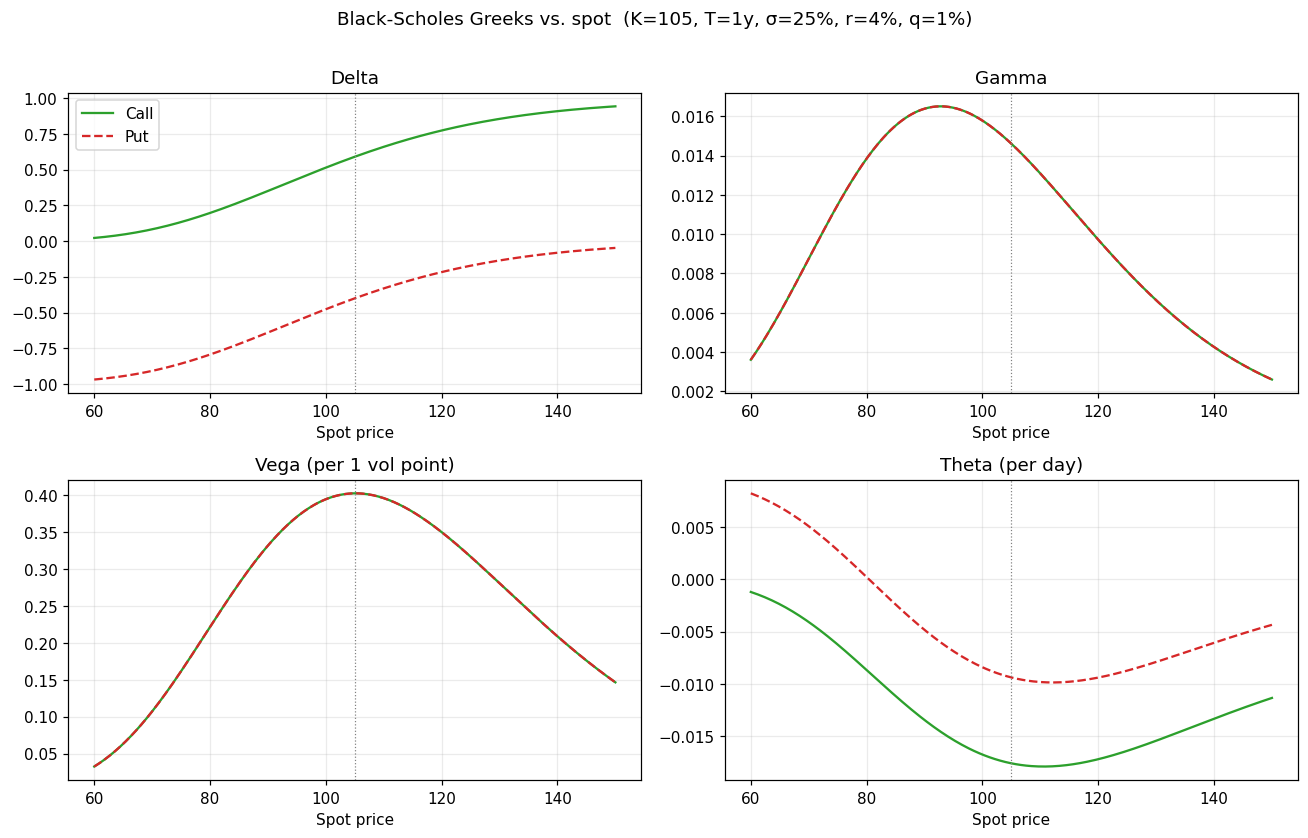

In [36]:
spots = np.linspace(60, 150, 300)
gc = bs_greeks(spots, K, T, r, sigma, q, call=True)
gp = bs_greeks(spots, K, T, r, sigma, q, call=False)

panels = [("delta", "Delta", 1.0),
          ("gamma", "Gamma", 1.0),
          ("vega",  "Vega (per 1 vol point)", 0.01),
          ("theta", "Theta (per day)", 1 / 365)]

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (key, title, scale) in zip(axes.ravel(), panels):
    ax.plot(spots, gc[key] * scale, color="tab:green", label="Call")
    ax.plot(spots, gp[key] * scale, color="tab:red", linestyle="--", label="Put")
    ax.axvline(K, color="gray", linewidth=0.8, linestyle=":")
    ax.set_title(title)
    ax.set_xlabel("Spot price")
axes[0, 0].legend()
fig.suptitle(f"Black-Scholes Greeks vs. spot  (K={K}, T={T:g}y, σ={sigma:.0%}, r={r:.0%}, q={q:.0%})", y=1.01)
plt.tight_layout()
plt.show()

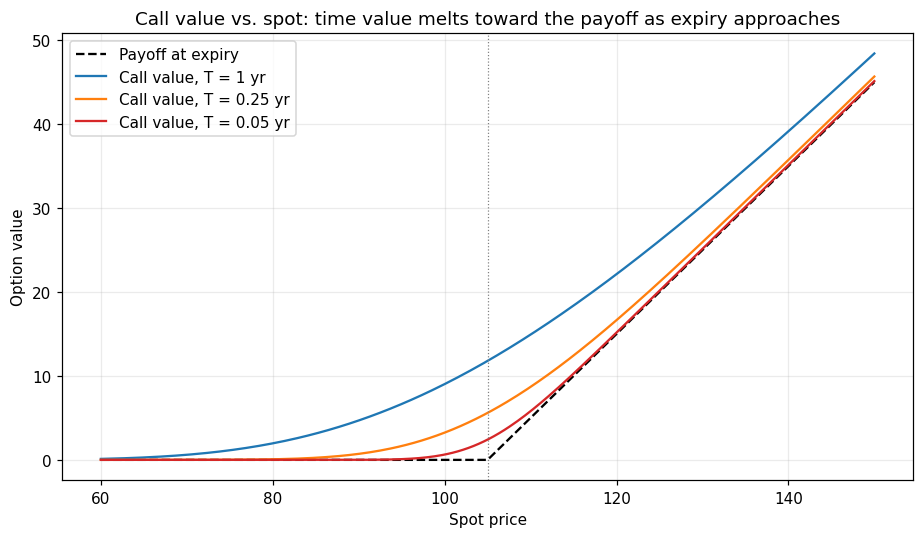

In [37]:
spots = np.linspace(60, 150, 300)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(spots, np.maximum(spots - K, 0), color="black", linestyle="--", label="Payoff at expiry")
for t_, c in [(1.0, "tab:blue"), (0.25, "tab:orange"), (0.05, "tab:red")]:
    ax.plot(spots, bs_price(spots, K, t_, r, sigma, q, call=True), color=c, label=f"Call value, T = {t_:g} yr")
ax.axvline(K, color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("Spot price")
ax.set_ylabel("Option value")
ax.set_title("Call value vs. spot: time value melts toward the payoff as expiry approaches")
ax.legend()
plt.tight_layout()
plt.show()

### Binomial convergence to Black-Scholes
For a European option, the tree should converge to the Black-Scholes price as the number of steps grows. The error falls from about 0.033 at 50 steps to under 0.001 at 3,200 steps. The convergence is not perfectly monotonic: it oscillates slightly depending on where the strike falls relative to the final layer of nodes.

In [38]:
print("Binomial (European call) convergence:")
for n in (50, 200, 800, 3200):
    b = binomial_price(S, K, T, r, sigma, q, steps=n)
    print(f"  steps={n:5d}  price={b:.4f}  error={b - bs_c:+.5f}")

Binomial (European call) convergence:
  steps=   50  price=9.0640  error=+0.03299
  steps=  200  price=9.0413  error=+0.01030
  steps=  800  price=9.0323  error=+0.00127
  steps= 3200  price=9.0318  error=+0.00073


### Visualizing binomial convergence
**Left:** absolute error vs. number of steps on log-log axes, with a $1/N$ reference line. **Right:** the signed error for 10 to 200 steps. The rapid even/odd zig-zag comes from where the strike lands relative to the final layer of nodes: the tree converges, but not monotonically.

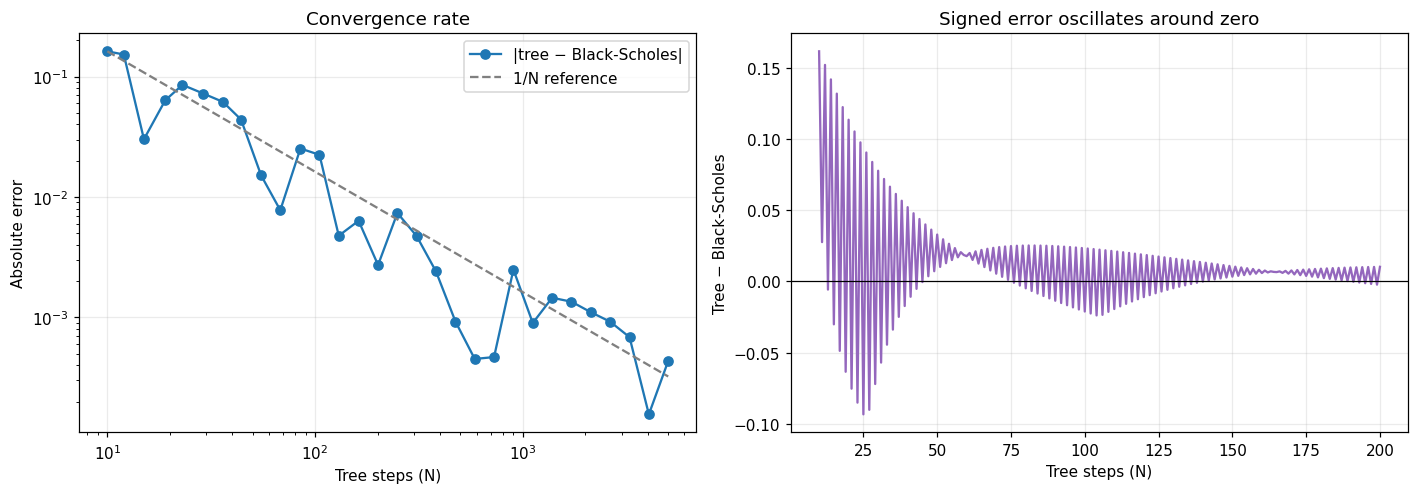

In [39]:
steps_grid = np.unique(np.logspace(1, 3.7, 30).astype(int))
errs = np.array([binomial_price(S, K, T, r, sigma, q, steps=n) - bs_c for n in steps_grid])

fine = np.arange(10, 201)
fine_errs = np.array([binomial_price(S, K, T, r, sigma, q, steps=n) - bs_c for n in fine])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].loglog(steps_grid, np.abs(errs), "o-", label="|tree − Black-Scholes|")
axes[0].loglog(steps_grid, np.abs(errs[0]) * steps_grid[0] / steps_grid, "--", color="gray", label="1/N reference")
axes[0].set_xlabel("Tree steps (N)")
axes[0].set_ylabel("Absolute error")
axes[0].set_title("Convergence rate")
axes[0].legend()

axes[1].plot(fine, fine_errs, color="tab:purple")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Tree steps (N)")
axes[1].set_ylabel("Tree − Black-Scholes")
axes[1].set_title("Signed error oscillates around zero")

plt.tight_layout()
plt.show()

### Monte Carlo vs. Black-Scholes
With 1,000,000 paths, the Monte Carlo estimate should land within its 95% confidence interval of the analytic price. Monte Carlo error shrinks at a rate of $1/\sqrt{N}$, so cutting the error in half requires four times as many paths. This slow convergence is why it is rarely used for plain vanillas, and why variance reduction matters.

In [40]:
mc, se = mc_price(S, K, T, r, sigma, q, n_paths=1_000_000, seed=42)
print(f"Monte Carlo call {mc:.4f} +/- {1.96 * se:.4f} (95% CI)")
print(f"Black-Scholes    {bs_c:.4f}")
print(f"Inside CI: {abs(mc - bs_c) <= 1.96 * se}")

Monte Carlo call 9.0391 +/- 0.0264 (95% CI)
Black-Scholes    9.0310
Inside CI: True


### Visualizing Monte Carlo convergence
**Left:** the Monte Carlo estimate with its 95% confidence band as the number of paths grows; the dashed line is the Black-Scholes price. **Right:** the standard error on log-log axes, which falls along the $1/\sqrt{N}$ reference line. Halving the error costs four times the paths.

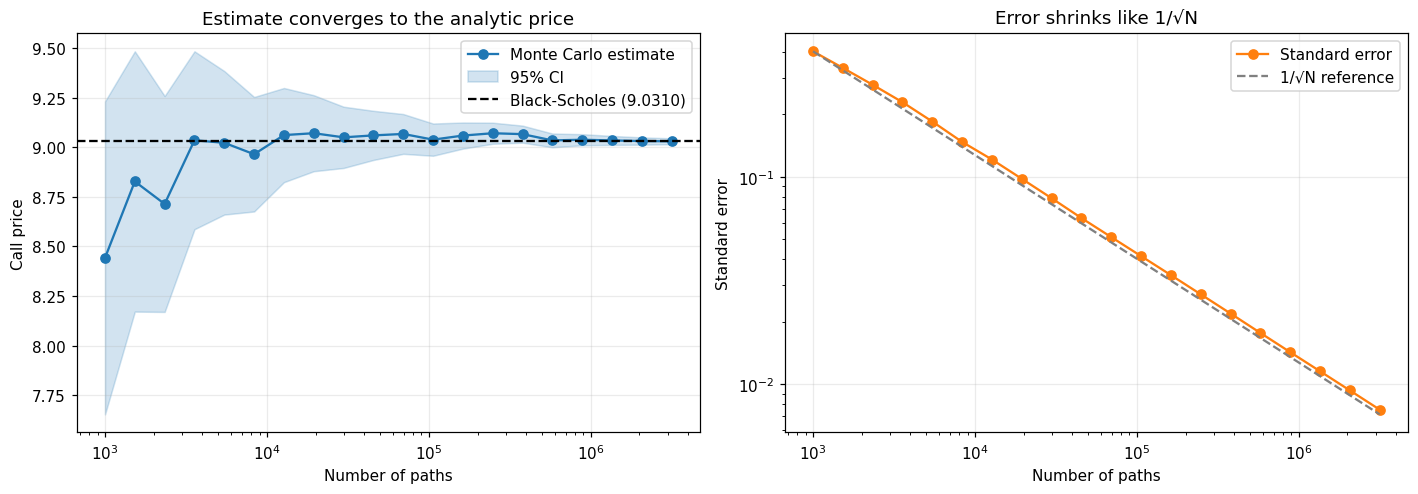

In [41]:
ns = np.unique(np.logspace(3, 6.5, 20).astype(int))
res = [mc_price(S, K, T, r, sigma, q, n_paths=n, seed=42) for n in ns]
means = np.array([m for m, _ in res])
ses = np.array([s for _, s in res])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].semilogx(ns, means, "o-", color="tab:blue", label="Monte Carlo estimate")
axes[0].fill_between(ns, means - 1.96 * ses, means + 1.96 * ses, color="tab:blue", alpha=0.2, label="95% CI")
axes[0].axhline(bs_c, color="black", linestyle="--", label=f"Black-Scholes ({bs_c:.4f})")
axes[0].set_xlabel("Number of paths")
axes[0].set_ylabel("Call price")
axes[0].set_title("Estimate converges to the analytic price")
axes[0].legend()

axes[1].loglog(ns, ses, "o-", color="tab:orange", label="Standard error")
axes[1].loglog(ns, ses[0] * np.sqrt(ns[0] / ns), "--", color="gray", label="1/√N reference")
axes[1].set_xlabel("Number of paths")
axes[1].set_ylabel("Standard error")
axes[1].set_title("Error shrinks like 1/√N")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Where the methods differ: early exercise and path dependence
These two examples show where Black-Scholes breaks down.

- **American vs. European put.** A deep in-the-money put (K = 120, r = 6%) is worth more if it can be exercised early, because cash received sooner earns interest. The tree captures this **early-exercise premium** of about 2.53; Black-Scholes cannot.
- **Arithmetic Asian call.** The payoff depends on the *average* price over the year rather than the final price. Averaging dampens volatility, so the Asian call (about 4.26) is much cheaper than the vanilla call (about 9.03). There is no closed form, so Monte Carlo is the natural tool.

In [42]:
eu = binomial_price(100, 120, 1.0, 0.06, 0.25, 0.0, call=False, american=False, steps=1000)
am = binomial_price(100, 120, 1.0, 0.06, 0.25, 0.0, call=False, american=True, steps=1000)
print(f"Put K=120: European {eu:.4f}  American {am:.4f}  premium {am - eu:.4f}")

asian, ase = mc_asian_price(S, K, T, r, sigma, q, seed=42)
print(f"Arithmetic Asian call {asian:.4f} +/- {1.96 * ase:.4f}  (vanilla {bs_c:.4f})")

Put K=120: European 18.3373  American 20.8705  premium 2.5333
Arithmetic Asian call 4.2580 +/- 0.0504  (vanilla 9.0310)


### Early exercise and path dependence in pictures
**American vs. European put (left plot below):** the shaded region is where the American put is worth exactly its intrinsic value, meaning the optimal move is to exercise immediately. A European put cannot do this, so its value dips below intrinsic value for deep in-the-money spots.

**Asian vs. vanilla call (second plot):** sample simulated paths on the left; on the right, the distribution of discounted payoffs. Averaging over the path pulls the Asian payoff toward the middle, so it has fewer large payoffs and a lower price. (Prices in the legend are Monte Carlo estimates from this 50,000-path sample, so they differ slightly from the exact Black-Scholes value.)

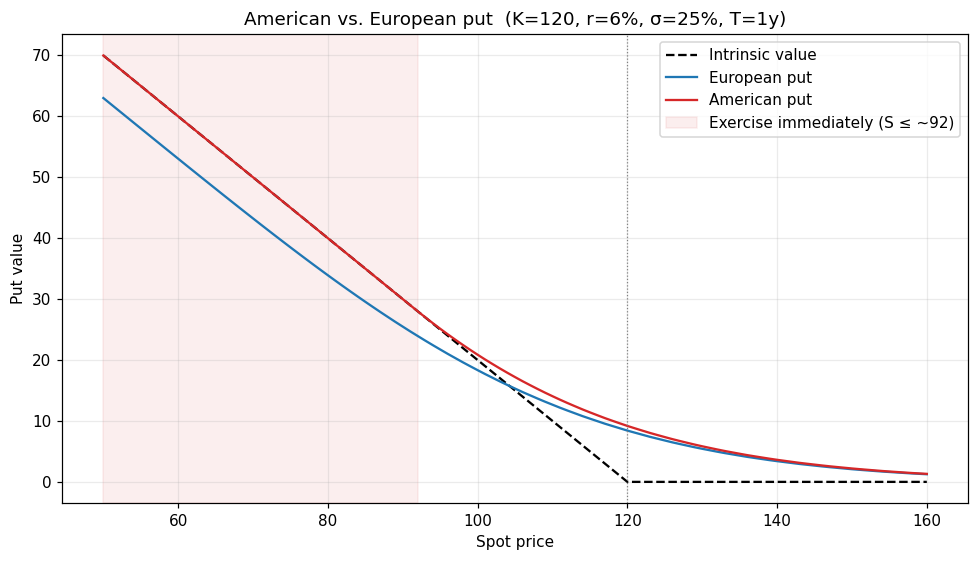

In [43]:
K_a, r_a, sig_a, T_a = 120, 0.06, 0.25, 1.0
spots_a = np.linspace(50, 160, 111)
eu_curve = np.array([binomial_price(s, K_a, T_a, r_a, sig_a, 0.0, call=False, american=False, steps=400) for s in spots_a])
am_curve = np.array([binomial_price(s, K_a, T_a, r_a, sig_a, 0.0, call=False, american=True, steps=400) for s in spots_a])
intrinsic = np.maximum(K_a - spots_a, 0)
exercise_now = am_curve <= intrinsic + 1e-9

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(spots_a, intrinsic, color="black", linestyle="--", label="Intrinsic value")
ax.plot(spots_a, eu_curve, color="tab:blue", label="European put")
ax.plot(spots_a, am_curve, color="tab:red", label="American put")
if exercise_now.any():
    s_star = spots_a[exercise_now].max()
    ax.axvspan(spots_a[0], s_star, color="tab:red", alpha=0.08, label=f"Exercise immediately (S ≤ ~{s_star:.0f})")
ax.axvline(K_a, color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("Spot price")
ax.set_ylabel("Put value")
ax.set_title(f"American vs. European put  (K={K_a}, r={r_a:.0%}, σ={sig_a:.0%}, T={T_a:g}y)")
ax.legend()
plt.tight_layout()
plt.show()

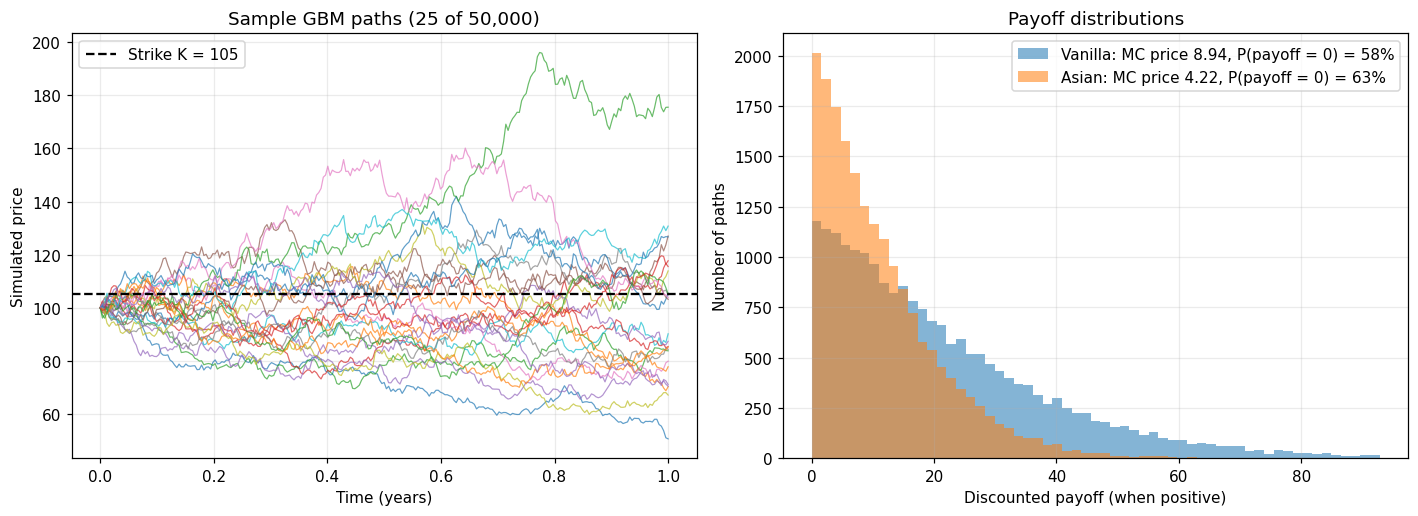

In [44]:
rng = np.random.default_rng(7)
n_paths, n_steps = 50_000, 252
dt = T / n_steps
z = rng.standard_normal((n_paths, n_steps))
paths = S * np.exp(np.cumsum((r - q - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z, axis=1))
disc = np.exp(-r * T)
vanilla_pay = disc * np.maximum(paths[:, -1] - K, 0)
asian_pay = disc * np.maximum(paths.mean(axis=1) - K, 0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
t_axis = np.linspace(0, T, n_steps + 1)
for p in paths[:25]:
    axes[0].plot(t_axis, np.concatenate([[S], p]), linewidth=0.8, alpha=0.7)
axes[0].axhline(K, color="black", linestyle="--", label=f"Strike K = {K}")
axes[0].set_xlabel("Time (years)")
axes[0].set_ylabel("Simulated price")
axes[0].set_title("Sample GBM paths (25 of 50,000)")
axes[0].legend()

bins = np.linspace(0, np.percentile(vanilla_pay[vanilla_pay > 0], 99.5), 60)
for pay, name, c in [(vanilla_pay, "Vanilla", "tab:blue"), (asian_pay, "Asian", "tab:orange")]:
    axes[1].hist(pay[pay > 0], bins=bins, alpha=0.55, color=c,
                 label=f"{name}: MC price {pay.mean():.2f}, P(payoff = 0) = {np.mean(pay == 0):.0%}")
axes[1].set_xlabel("Discounted payoff (when positive)")
axes[1].set_ylabel("Number of paths")
axes[1].set_title("Payoff distributions")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Method comparison — accuracy vs. speed
Each method trades accuracy, speed, and flexibility. The table prices the same European call with every engine, then records the error against the Black-Scholes benchmark and the average wall-clock runtime (exact timings vary with the Colab machine).

- **Black-Scholes** is exact and effectively instantaneous, but only handles European payoffs.
- **The tree** converges as steps increase and handles early exercise. Its cost grows roughly with the *square* of the step count.
- **Monte Carlo** has statistical rather than discretization error (shrinking like $1/\sqrt{N}$) and is the most flexible, which is why it is the tool for exotic payoffs.

In [45]:
def timed(fn, n_rep=1):
    t0 = time.perf_counter()
    for _ in range(n_rep):
        out = fn()
    return out, (time.perf_counter() - t0) / n_rep * 1000   # milliseconds

rows = []
out, ms = timed(lambda: bs_price(S, K, T, r, sigma, q, True), n_rep=2000)
rows.append(("Black-Scholes (closed form)", out, np.nan, ms))
for n in (200, 1000, 5000):
    out, ms = timed(lambda n=n: binomial_price(S, K, T, r, sigma, q, steps=n), n_rep=3)
    rows.append((f"Binomial tree ({n:,} steps)", out, np.nan, ms))
for n in (100_000, 1_000_000):
    (p_mc, se_mc), ms = timed(lambda n=n: mc_price(S, K, T, r, sigma, q, n_paths=n, seed=42), n_rep=3)
    rows.append((f"Monte Carlo ({n:,} paths)", p_mc, se_mc, ms))

summary = pd.DataFrame(rows, columns=["Method", "Call price", "Std. error", "Runtime (ms)"])
summary["Error vs. BS"] = summary["Call price"] - bs_c

display(summary.style.format({"Call price": "{:.4f}", "Std. error": "{:.4f}",
                              "Error vs. BS": "{:+.5f}", "Runtime (ms)": "{:,.3f}"},
                             na_rep="—").hide(axis="index"))

Method,Call price,Std. error,Runtime (ms),Error vs. BS
Black-Scholes (closed form),9.0310,—,0.507,+0.00000
Binomial tree (200 steps),9.0413,—,6.368,+0.01030
"Binomial tree (1,000 steps)",9.0300,—,24.354,-0.00104
"Binomial tree (5,000 steps)",9.0309,—,140.504,-0.00016
"Monte Carlo (100,000 paths)",9.0549,0.0427,4.760,+0.02388
"Monte Carlo (1,000,000 paths)",9.0391,0.0134,26.663,+0.00805


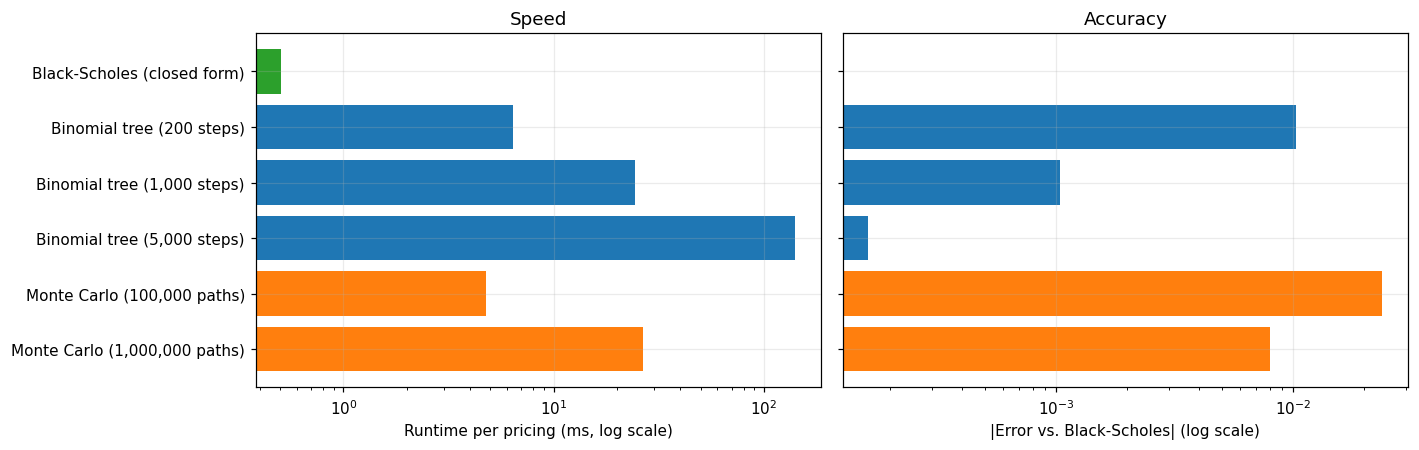

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
colors = ["tab:green"] + ["tab:blue"] * 3 + ["tab:orange"] * 2
axes[0].barh(summary["Method"], summary["Runtime (ms)"], color=colors)
axes[0].set_xscale("log")
axes[0].invert_yaxis()
axes[0].set_xlabel("Runtime per pricing (ms, log scale)")
axes[0].set_title("Speed")

axes[1].barh(summary["Method"], summary["Error vs. BS"].abs(), color=colors)
axes[1].set_xscale("log")
axes[1].invert_yaxis()
axes[1].set_xlabel("|Error vs. Black-Scholes| (log scale)")
axes[1].set_title("Accuracy")
axes[1].set_yticklabels([])

plt.tight_layout()
plt.show()

## 8. Live market data — implied volatility, the smile, and model vs. market
Up to now every input was hypothetical. Here we point the engine at a **real option chain** pulled with `yfinance` (free data, delayed about 15 minutes). The steps:

1. Pull the spot price, price history, a risk-free rate proxy (13-week T-bill, `^IRX`), and a trailing dividend yield
2. Load one expiry's option chain and keep out-of-the-money options with usable quotes
3. Invert Black-Scholes with Brent's method to get each contract's **implied volatility**
4. Plot the **volatility smile** against realized volatility
5. Price the same contracts with all three engines using one flat volatility and compare them with market mid-prices
6. Translate the model into trader-friendly outputs: expected move, per-contract Greeks, and a P&L scenario grid

*Data notes:* change `TICKER` to any optionable symbol. Outside market hours quotes can be missing or stale, in which case the code falls back to last-traded prices and says so. A saved snapshot in `data/` lets the notebook rerun offline (see 8.0). Free data is for analysis and demonstration, not for trading.

### 8.0 Live data vs. a saved snapshot
Free market data changes every day, so a notebook that only reads live data cannot reproduce its own results later. This section works in two modes:

- **Live mode** (`USE_SNAPSHOT = False`, the default): pull the spot price, history, and option chain from `yfinance`.
- **Snapshot mode** (`USE_SNAPSHOT = True`): load the spot, rate, dividend yield, expiry, price history, and option chain saved in `data/`, so the notebook runs offline and gives the same numbers every time.

If the live pull fails (network error, rate limit, empty response), the notebook falls back to the snapshot automatically and says so. After each successful live pull with real bid/ask quotes, step 8.2b saves a fresh snapshot. It never saves a snapshot built from stale last-traded prices.

### 8.1 Pull spot, rates, dividends, and realized volatility
- **Risk-free rate:** the 13-week T-bill yield (`^IRX`), a standard short-horizon proxy.
- **Dividend yield $q$:** trailing 12-month dividends divided by spot, fed to the models as a continuous yield.
- **Realized volatility:** annualized standard deviation of the last 30 daily log returns, a *backward-looking* estimate to compare with the market's *forward-looking* implied volatility.

Data source: live (yfinance)
AAPL   spot = $349.22   r = 4.12%   q = 0.23%
Expiry 2026-12-11  (31 days, T = 0.085 yr)   30-day realized vol = 23.0%


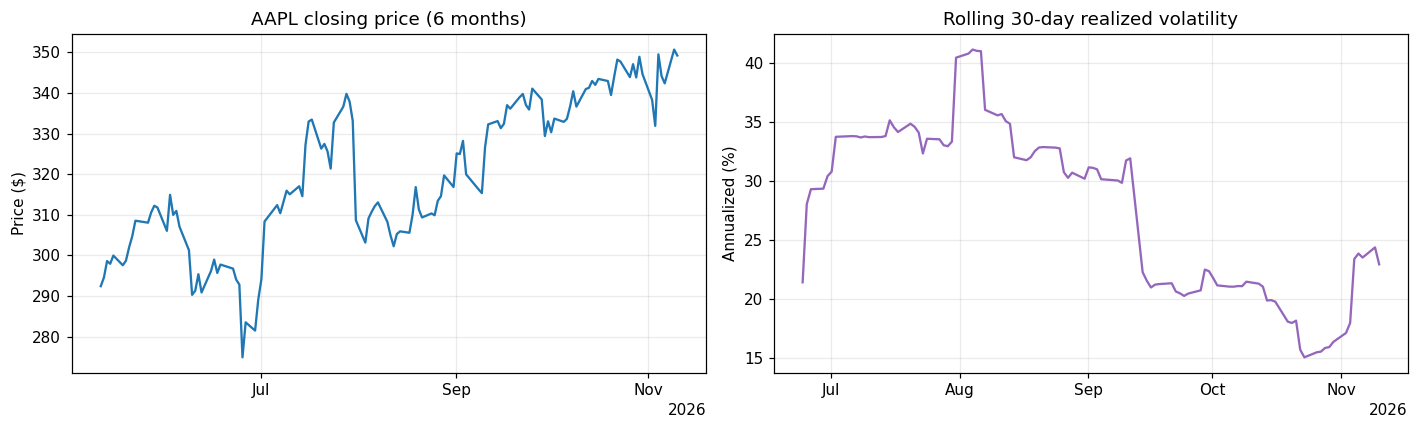

In [47]:
import json, os
import matplotlib.dates as mdates

TICKER = "AAPL"        # change to any optionable ticker, e.g. "NVDA", "SPY", "TSLA"
MIN_DAYS = 30          # target expiry at least this many days out
USE_SNAPSHOT = False   # True = skip yfinance and load the saved snapshot from SNAP_DIR (see 8.0)
SNAP_DIR = "data"      # folder holding the saved snapshot


def get_risk_free(default=0.04):
    try:
        irx = yf.Ticker("^IRX").history(period="5d")["Close"].dropna()
        return float(irx.iloc[-1]) / 100          # ^IRX is quoted in percent
    except Exception:
        return default


def get_div_yield(ticker_obj, spot):
    try:
        d = ticker_obj.dividends
        if len(d) == 0:
            return 0.0
        cutoff = pd.Timestamp.now(tz=d.index.tz) - pd.Timedelta(days=365)
        return float(d[d.index >= cutoff].sum()) / spot
    except Exception:
        return 0.0


def pick_expiry(ticker_obj, min_days):
    today = pd.Timestamp.today().normalize()
    expiries = ticker_obj.options
    for e in expiries:
        days = (pd.Timestamp(e) - today).days
        if days >= min_days:
            return e, days
    return expiries[-1], (pd.Timestamp(expiries[-1]) - today).days


def load_snapshot(ticker, snap_dir=SNAP_DIR):
    try:
        with open(f"{snap_dir}/{ticker}_snapshot.json") as f:
            meta = json.load(f)
        hist = pd.read_csv(f"{snap_dir}/{ticker}_history.csv", index_col=0)
    except FileNotFoundError:
        raise RuntimeError(f"No saved snapshot for {ticker} in '{snap_dir}/'. Run once with "
                           f"USE_SNAPSHOT = False during market hours to create one.")
    hist.index = pd.to_datetime(hist.index, utc=True)
    return meta, hist


tk, meta = None, None
data_source = "live (yfinance)"
if not USE_SNAPSHOT:
    try:
        tk = yf.Ticker(TICKER)
        hist = tk.history(period="6mo")
        if hist.empty:
            raise ValueError("no price history returned")
        S_mkt = float(hist["Close"].iloc[-1])
        r_mkt = get_risk_free()
        q_mkt = get_div_yield(tk, S_mkt)
        expiry, days_to_exp = pick_expiry(tk, MIN_DAYS)
    except Exception as err:
        print(f"Live data pull failed ({err}); loading the saved snapshot instead.")
        USE_SNAPSHOT = True
if USE_SNAPSHOT:
    meta, hist = load_snapshot(TICKER)
    S_mkt, r_mkt, q_mkt = meta["spot"], meta["r"], meta["q"]
    expiry, days_to_exp = meta["expiry"], meta["days_to_exp"]
    data_source = f"saved snapshot ({meta['as_of']})"
T_mkt = days_to_exp / 365

log_ret = np.log(hist["Close"]).diff().dropna()
rv_30 = float(log_ret.tail(30).std() * np.sqrt(252))
rv_roll = log_ret.rolling(30).std() * np.sqrt(252)

print(f"Data source: {data_source}")
print(f"{TICKER}   spot = ${S_mkt:,.2f}   r = {r_mkt:.2%}   q = {q_mkt:.2%}")
print(f"Expiry {expiry}  ({days_to_exp} days, T = {T_mkt:.3f} yr)   30-day realized vol = {rv_30:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist.index, hist["Close"], color="tab:blue")
axes[0].set_title(f"{TICKER} closing price (6 months)")
axes[0].set_ylabel("Price ($)")
axes[1].plot(rv_roll.index, rv_roll * 100, color="tab:purple")
axes[1].set_title("Rolling 30-day realized volatility")
axes[1].set_ylabel("Annualized (%)")
for ax in axes:                                   # readable, non-overlapping date labels
    locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
plt.tight_layout()
plt.show()

### 8.2 Load the option chain and solve for implied volatility
We keep **out-of-the-money** options only (puts below spot, calls at or above it). They are the most liquid, and because US equity options are American-style, their early-exercise premium is small, which makes a Black-Scholes inversion a reasonable approximation. We also keep strikes within ±15% of spot and drop contracts whose bid-ask spread exceeds 50% of the mid-price.

The **implied volatility** of a contract is the $\sigma$ that makes the Black-Scholes price equal the market mid-price. There is no closed-form inverse, so we find it with Brent's method on $[0.01\%,\ 500\%]$. Our result is shown next to Yahoo's own reported IV as a sanity check.

In [48]:
def load_chain(ticker_obj, expiry, S0, lo=0.85, hi=1.15, max_spread=0.5):
    ch = ticker_obj.option_chain(expiry)
    calls = ch.calls.assign(type="call")
    puts = ch.puts.assign(type="put")
    df = pd.concat([puts[puts["strike"] < S0], calls[calls["strike"] >= S0]])
    df = df[(df["strike"] >= lo * S0) & (df["strike"] <= hi * S0)].copy()

    quoted = df[(df["bid"] > 0) & (df["ask"] > 0)].copy()
    if len(quoted) >= 8:
        quoted["mid"] = (quoted["bid"] + quoted["ask"]) / 2
        quoted["half_spread"] = (quoted["ask"] - quoted["bid"]) / 2
        quoted = quoted[(quoted["ask"] - quoted["bid"]) / quoted["mid"] <= max_spread]
        out, source = quoted, "bid/ask mid-price"
    else:
        out = df[df["lastPrice"] > 0].copy()
        out["mid"] = out["lastPrice"]
        out["half_spread"] = 0.0
        source = "last traded price (live quotes unavailable, market may be closed)"
    return out.sort_values("strike").reset_index(drop=True), source


def implied_vol(price, S0, K0, T0, r0, q0, call):
    fwd_intrinsic = (S0 * np.exp(-q0 * T0) - K0 * np.exp(-r0 * T0)) if call else \
                    (K0 * np.exp(-r0 * T0) - S0 * np.exp(-q0 * T0))
    if price <= max(fwd_intrinsic, 0) + 1e-6:      # price below no-arbitrage bound: no valid IV
        return np.nan
    try:
        return brentq(lambda s: bs_price(S0, K0, T0, r0, s, q0, call) - price, 1e-4, 5.0)
    except ValueError:
        return np.nan


if USE_SNAPSHOT:
    chain = pd.read_csv(f"{SNAP_DIR}/{TICKER}_chain.csv")
    price_source = meta["price_source"] + ", saved snapshot"
else:
    chain, price_source = load_chain(tk, expiry, S_mkt)
chain["iv"] = [implied_vol(m, S_mkt, k, T_mkt, r_mkt, q_mkt, t == "call")
               for m, k, t in zip(chain["mid"], chain["strike"], chain["type"])]
chain = chain.dropna(subset=["iv"]).reset_index(drop=True)

print(f"{len(chain)} contracts with valid implied vol  |  prices from: {price_source}")
show = chain[["type", "strike", "bid", "ask", "mid", "iv", "impliedVolatility", "volume", "openInterest"]]
show = show.rename(columns={"iv": "IV (ours)", "impliedVolatility": "IV (Yahoo)"})
display(show.head(15).style.format({"strike": "{:.1f}", "bid": "{:.2f}", "ask": "{:.2f}", "mid": "{:.2f}",
                                    "IV (ours)": "{:.1%}", "IV (Yahoo)": "{:.1%}"}, na_rep="—").hide(axis="index"))

20 contracts with valid implied vol  |  prices from: bid/ask mid-price


type,strike,bid,ask,mid,IV (ours),IV (Yahoo),volume,openInterest
put,300.0,0.75,0.86,0.80,34.0%,33.4%,20.000000,909
put,305.0,0.93,1.03,0.98,32.5%,31.8%,59.000000,411
put,310.0,1.19,1.30,1.25,31.3%,30.5%,10.000000,893
put,315.0,1.50,1.69,1.59,30.2%,29.5%,9.000000,186
put,320.0,1.88,2.14,2.01,28.9%,28.3%,74.000000,582
put,325.0,2.48,2.74,2.61,27.8%,27.1%,35.000000,445
put,330.0,3.25,3.40,3.33,26.7%,25.6%,176.000000,450
put,335.0,4.30,4.55,4.42,26.0%,25.0%,35.000000,330
put,340.0,5.60,5.95,5.78,25.3%,24.3%,92.000000,294
put,345.0,7.25,7.70,7.47,24.6%,23.6%,169.000000,246


### 8.2b Save a snapshot
Run this cell right after 8.2. It saves the market inputs and the option chain to `data/` (and, in Colab, downloads them as `snapshot_data.zip`). Commit the `data/` folder to the repository so anyone can reproduce the results.

In [49]:
SAVE_SNAPSHOT = True      # write the inputs used above to SNAP_DIR so the notebook can be rerun offline

if SAVE_SNAPSHOT and not USE_SNAPSHOT:
    if not price_source.startswith("bid/ask"):
        print("Snapshot NOT saved: these quotes are stale last-traded prices. Rerun during market hours "
              "(or soon after the close) to capture clean bid/ask quotes.")
    else:
        os.makedirs(SNAP_DIR, exist_ok=True)
        meta_out = {"ticker": TICKER,
                    "as_of": pd.Timestamp.now(tz="America/New_York").strftime("%Y-%m-%d %H:%M ET"),
                    "spot": S_mkt, "r": r_mkt, "q": q_mkt,
                    "expiry": expiry, "days_to_exp": days_to_exp, "price_source": price_source}
        with open(f"{SNAP_DIR}/{TICKER}_snapshot.json", "w") as f:
            json.dump(meta_out, f, indent=2)
        hist[["Close"]].to_csv(f"{SNAP_DIR}/{TICKER}_history.csv")
        chain.drop(columns=["iv"]).to_csv(f"{SNAP_DIR}/{TICKER}_chain.csv", index=False)
        print(f"Saved snapshot to {SNAP_DIR}/ ({len(chain)} contracts, as of {meta_out['as_of']}).")
        try:                                              # in Colab, also download it as a zip
            from google.colab import files
            import shutil
            shutil.make_archive("snapshot_data", "zip", SNAP_DIR)
            files.download("snapshot_data.zip")
        except ImportError:
            pass
elif USE_SNAPSHOT:
    print("Running from the saved snapshot, so nothing new to save.")

Saved snapshot to data/ (20 contracts, as of 2026-11-10 15:47 ET).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 8.3 The volatility smile
If Black-Scholes' constant-volatility assumption held, implied volatility would be flat across strikes. Real equity options usually show a **skew**: out-of-the-money puts trade at higher implied volatility than at-the-money options, because investors pay up for downside protection. The dashed line is 30-day realized volatility. The gap between implied and realized is the **volatility risk premium**, which has historically tended to be positive because option sellers demand compensation for bearing tail risk.

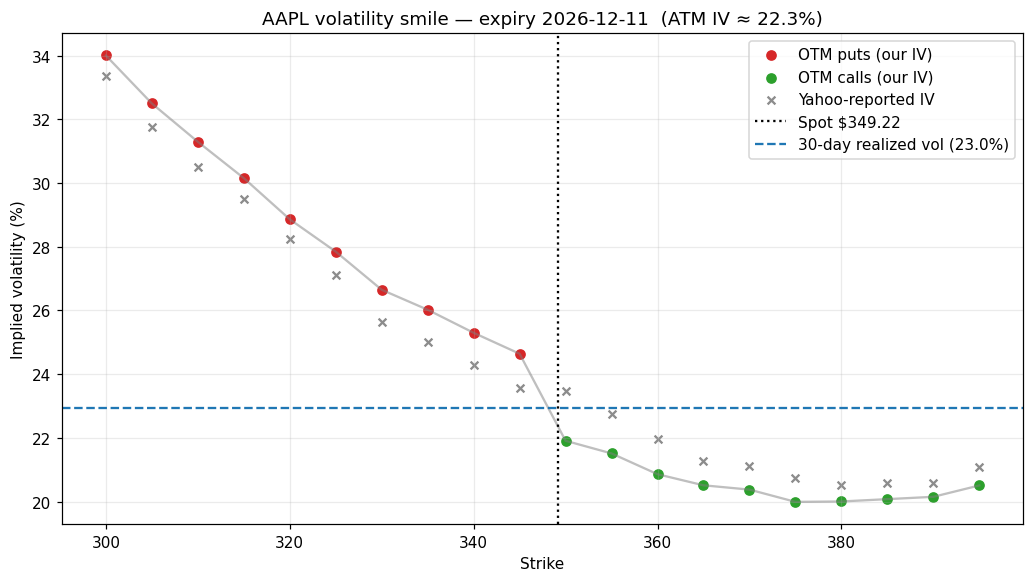

In [50]:
atm_iv = float(np.interp(S_mkt, chain["strike"], chain["iv"]))
puts_ = chain[chain["type"] == "put"]
calls_ = chain[chain["type"] == "call"]
yahoo_ok = chain[chain["impliedVolatility"] > 0.02]

fig, ax = plt.subplots(figsize=(9.5, 5.4))
ax.plot(chain["strike"], chain["iv"] * 100, "-", color="gray", alpha=0.5)
ax.scatter(puts_["strike"], puts_["iv"] * 100, color="tab:red", s=36, label="OTM puts (our IV)")
ax.scatter(calls_["strike"], calls_["iv"] * 100, color="tab:green", s=36, label="OTM calls (our IV)")
ax.scatter(yahoo_ok["strike"], yahoo_ok["impliedVolatility"] * 100, marker="x", color="black",
           alpha=0.45, s=26, label="Yahoo-reported IV")
ax.axvline(S_mkt, color="black", linestyle=":", label=f"Spot ${S_mkt:,.2f}")
ax.axhline(rv_30 * 100, color="tab:blue", linestyle="--", label=f"30-day realized vol ({rv_30:.1%})")
ax.set_xlabel("Strike")
ax.set_ylabel("Implied volatility (%)")
ax.set_title(f"{TICKER} volatility smile — expiry {expiry}  (ATM IV ≈ {atm_iv:.1%})")
ax.legend()
plt.tight_layout()
plt.show()

### 8.4 Model vs. market prices
We now price a spread of strikes with **all three engines using one flat volatility**: the at-the-money implied vol read off the smile. Black-Scholes and Monte Carlo treat the options as European; the tree prices them as American, which is appropriate for US equity options. The chart plots *model minus market* against the bid-ask half-spread: an error inside the grey band is indistinguishable from quoting noise.

A flat $\sigma$ fits near the money by construction, but the error grows toward the wings. That is a direct consequence of the smile, and the main reason practitioners quote prices in implied volatility rather than dollars.

Type,Strike,Market mid,Black-Scholes,Tree (American),Monte Carlo,BS − mkt,Tree − mkt,MC − mkt,Half-spread
put,300.0,0.80,0.06,0.06,0.06,-0.75,-0.75,-0.74,0.05
put,305.0,0.98,0.13,0.13,0.13,-0.85,-0.85,-0.85,0.05
put,310.0,1.25,0.25,0.25,0.26,-1.00,-1.00,-0.99,0.06
put,315.0,1.59,0.46,0.46,0.47,-1.13,-1.13,-1.12,0.09
put,325.0,2.61,1.35,1.35,1.37,-1.26,-1.26,-1.24,0.13
put,330.0,3.33,2.13,2.15,2.15,-1.19,-1.18,-1.17,0.07
put,335.0,4.42,3.23,3.25,3.26,-1.19,-1.17,-1.17,0.12
put,340.0,5.78,4.70,4.74,4.72,-1.08,-1.04,-1.06,0.18
call,350.0,9.07,9.25,9.25,9.27,0.17,0.18,0.19,0.23
call,355.0,6.67,7.00,7.01,7.03,0.33,0.33,0.35,0.17


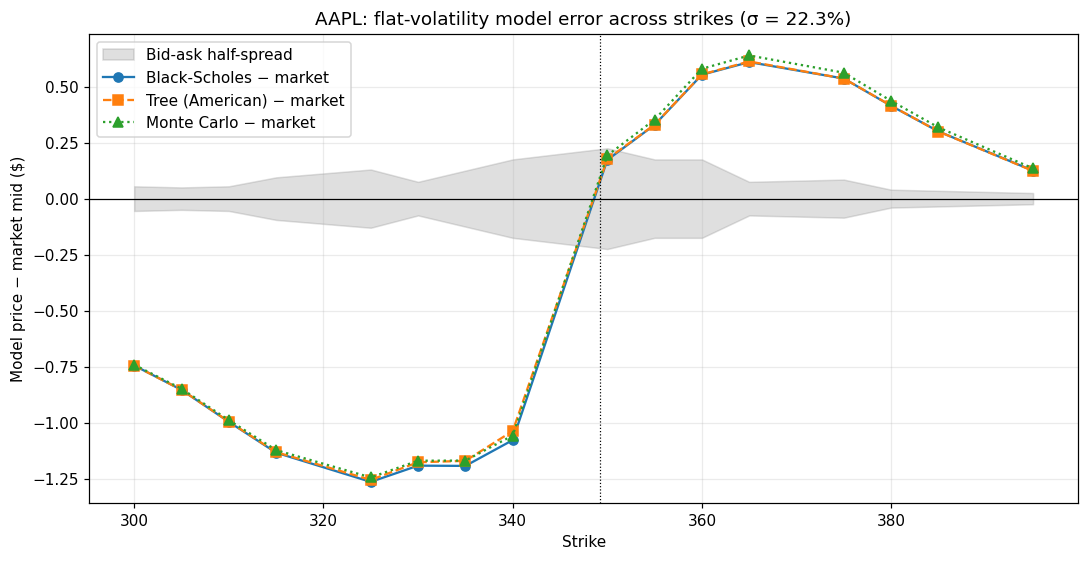

In [51]:
SIGMA_FLAT = atm_iv
idx = np.linspace(0, len(chain) - 1, min(16, len(chain))).astype(int)
sample = chain.iloc[np.unique(idx)]

rows = []
for _, row in sample.iterrows():
    is_call = row["type"] == "call"
    k_ = float(row["strike"])
    bs_p = bs_price(S_mkt, k_, T_mkt, r_mkt, SIGMA_FLAT, q_mkt, call=is_call)
    tree_p = binomial_price(S_mkt, k_, T_mkt, r_mkt, SIGMA_FLAT, q_mkt, call=is_call, american=True, steps=500)
    mc_p, _ = mc_price(S_mkt, k_, T_mkt, r_mkt, SIGMA_FLAT, q_mkt, call=is_call, n_paths=200_000, seed=42)
    rows.append({"Type": row["type"], "Strike": k_, "Market mid": row["mid"],
                 "Black-Scholes": bs_p, "Tree (American)": tree_p, "Monte Carlo": mc_p,
                 "BS − mkt": bs_p - row["mid"], "Tree − mkt": tree_p - row["mid"],
                 "MC − mkt": mc_p - row["mid"], "Half-spread": row["half_spread"]})
comp = pd.DataFrame(rows)

display(comp.style.format({c: "{:.2f}" for c in comp.columns if c not in ("Type", "Strike")} | {"Strike": "{:.1f}"})
        .hide(axis="index"))

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.fill_between(comp["Strike"], -comp["Half-spread"], comp["Half-spread"], color="gray", alpha=0.25,
                label="Bid-ask half-spread")
ax.plot(comp["Strike"], comp["BS − mkt"], "o-", label="Black-Scholes − market")
ax.plot(comp["Strike"], comp["Tree − mkt"], "s--", label="Tree (American) − market")
ax.plot(comp["Strike"], comp["MC − mkt"], "^:", label="Monte Carlo − market")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(S_mkt, color="black", linestyle=":", linewidth=0.8)
ax.set_xlabel("Strike")
ax.set_ylabel("Model price − market mid ($)")
ax.set_title(f"{TICKER}: flat-volatility model error across strikes (σ = {SIGMA_FLAT:.1%})")
ax.legend()
plt.tight_layout()
plt.show()

### 8.5 Reading the market: expected move, implied vs. realized, and Greeks
Three things a trader reads off the model:

- **Expected move:** a 1-standard-deviation range for the underlying through expiry, $S\,\sigma_{ATM}\sqrt{T}$.
- **Implied vs. realized volatility:** if implied is well above realized, options are pricing in more movement than the stock has recently delivered (and vice versa). It is a signal to investigate, not a trading rule.
- **Per-contract Greeks:** how much a single at-the-money call (100 shares) gains or loses for a $1 move, a 1-point change in volatility, and one day of time decay.

In [52]:
expected_move = S_mkt * atm_iv * np.sqrt(T_mkt)
print(f"ATM implied vol : {atm_iv:.1%}")
print(f"30-day realized : {rv_30:.1%}   (implied − realized = {(atm_iv - rv_30) * 100:+.1f} vol points)")
print(f"1-sigma expected move to {expiry}: ±${expected_move:,.2f}  "
      f"({S_mkt - expected_move:,.2f} to {S_mkt + expected_move:,.2f}, ±{expected_move / S_mkt:.1%})")

k_atm = float(chain.loc[(chain["strike"] - S_mkt).abs().idxmin(), "strike"])
g_atm = bs_greeks(S_mkt, k_atm, T_mkt, r_mkt, atm_iv, q_mkt, call=True)
call_px = bs_price(S_mkt, k_atm, T_mkt, r_mkt, atm_iv, q_mkt, call=True)

per_share = {"Model value ($)": call_px,
             "Delta ($ per $1 move in stock)": g_atm["delta"],
             "Gamma (change in delta per $1)": g_atm["gamma"],
             "Vega ($ per 1 vol point)": g_atm["vega"] / 100,
             "Theta ($ per day)": g_atm["theta"] / 365,
             "Rho ($ per 1% rate move)": g_atm["rho"] / 100}
greeks_tbl = pd.DataFrame({"Per share": per_share.values(),
                           "Per contract (×100)": [v * 100 for v in per_share.values()]},
                          index=per_share.keys())
print(f"\nLong 1 {TICKER} {expiry} {k_atm:g} call (priced at ATM implied vol):")
display(greeks_tbl.style.format("{:,.4f}"))

ATM implied vol : 22.3%
30-day realized : 23.0%   (implied − realized = -0.6 vol points)
1-sigma expected move to 2026-12-11: ±$22.73  (326.49 to 371.95, ±6.5%)

Long 1 AAPL 2026-12-11 350 call (priced at ATM implied vol):


,Per share,Per contract (×100)
Model value ($),9.2479,924.7850
Delta ($ per $1 move in stock),0.5194,51.9429
Gamma (change in delta per $1),0.0175,1.7526
Vega ($ per 1 vol point),0.4055,40.5451
Theta ($ per day),-0.1643,-16.4328
Rho ($ per 1% rate move),0.1462,14.6207


### 8.6 Scenario analysis: P&L of a long call
A pricing model is most useful when it answers "what happens to my position if...?". The grid below reprices the at-the-money call after **7 days** for combinations of a move in the stock (columns) and a change in implied volatility (rows), holding everything else fixed. The value shown is profit or loss per contract versus today's model value.

Read it as the Greeks working together: delta and gamma drive the left-right pattern, vega the up-down pattern, and theta is the cost of waiting that pulls the whole grid down.

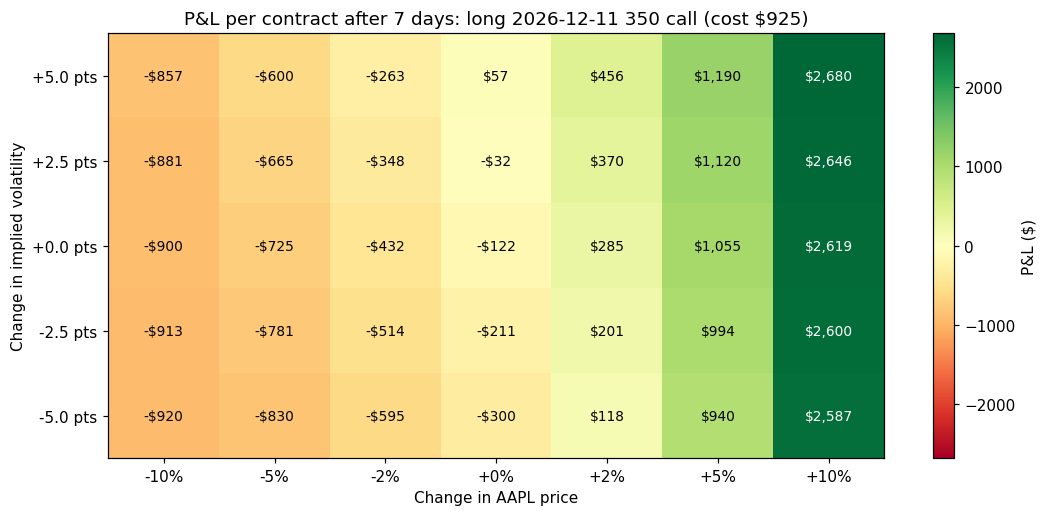

In [53]:
spot_moves = np.array([-0.10, -0.05, -0.02, 0.0, 0.02, 0.05, 0.10])
vol_moves = np.array([-0.05, -0.025, 0.0, 0.025, 0.05])
days_fwd = 7
T_new = T_mkt - days_fwd / 365

pnl = np.array([[(bs_price(S_mkt * (1 + dS), k_atm, T_new, r_mkt, max(atm_iv + dv, 0.01), q_mkt, call=True)
                  - call_px) * 100
                 for dS in spot_moves] for dv in vol_moves])

fig, ax = plt.subplots(figsize=(10, 4.8))
vmax = np.abs(pnl).max()
im = ax.imshow(pnl, cmap="RdYlGn", vmin=-vmax, vmax=vmax, aspect="auto", origin="lower")
ax.set_xticks(range(len(spot_moves)))
ax.set_xticklabels([f"{m:+.0%}" for m in spot_moves])
ax.set_yticks(range(len(vol_moves)))
ax.set_yticklabels([f"{v * 100:+.1f} pts" for v in vol_moves])
for i in range(pnl.shape[0]):
    for j in range(pnl.shape[1]):
        v = pnl[i, j]
        ax.text(j, i, f"{'-' if v < 0 else ''}${abs(v):,.0f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 * vmax else "black")
ax.grid(False)
ax.set_xlabel(f"Change in {TICKER} price")
ax.set_ylabel("Change in implied volatility")
ax.set_title(f"P&L per contract after {days_fwd} days: long {expiry} {k_atm:g} call (cost ${call_px * 100:,.0f})")
plt.colorbar(im, ax=ax, label="P&L ($)")
plt.tight_layout()
plt.show()

## 9. Delta-hedging a short option — what the implied-vs-realized gap is worth in dollars
Section 8 ended with a number: implied volatility minus realized volatility. Here we turn that gap into **profit and loss**. The experiment:

1. **Sell** one at-the-money call at the market's implied volatility $\sigma_{imp}$ and collect the Black-Scholes premium.
2. **Delta-hedge**: hold $\Delta$ shares of stock against the short call, and rebalance on a fixed schedule (daily by default). Financing and dividends are tracked in a cash account.
3. **Simulate** the stock under a *realized* volatility $\sigma_{real}$ that may differ from $\sigma_{imp}$, and record the hedger's final P&L (discounted to today) on each path.

With continuous hedging, the seller's P&L is not random in the usual sense. It is driven entirely by the gap between the two volatilities, weighted by the option's dollar gamma:

$$\text{P\&L} \;\approx\; \tfrac12 \int_0^T e^{-rt}\,\Gamma_t\, S_t^2\,\big(\sigma_{imp}^2 - \sigma_{real}^2\big)\,dt$$

If the stock realizes *less* volatility than the option priced in, the seller keeps the difference; if it realizes *more*, the seller loses. Integrating dollar gamma over time gives vega, so a handy rule of thumb is

$$\mathbb{E}[\text{P\&L}] \;\approx\; \text{Vega} \times (\sigma_{imp} - \sigma_{real}).$$

Real hedging is done at discrete times, which adds noise on top of that average. The next two sections measure both effects.

*Setup:* this section reuses the live inputs from Section 8 (`S_mkt`, `k_atm`, `T_mkt`, `r_mkt`, `q_mkt`, `atm_iv`, `rv_30`), so run Section 8 first. The stock follows geometric Brownian motion with drift $r - q$ and a **constant** volatility $\sigma_{real}$. There are no transaction costs, so the results are an idealized benchmark and not a trading forecast.

### 9.1 The hedging simulation
`delta_hedge_pnl` simulates `n_paths` stock paths, runs the hedge on every path at once, and returns each path's final P&L per share, discounted to today. The hedger always computes delta with the **implied** volatility, because that is the volatility the option was sold at.

In [54]:
def delta_hedge_pnl(S0, K, T, r, sigma_imp, sigma_real, q=0.0, n_steps=22,
                    n_paths=20_000, mu=None, seed=None):
    """Short one European call sold at the Black-Scholes price (sigma_imp), delta-hedged
    at n_steps equally spaced times. The stock follows GBM with volatility sigma_real and
    drift mu (default r - q). Returns the discounted final P&L per share, one value per path."""
    mu = (r - q) if mu is None else mu
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    z = rng.standard_normal((n_paths, n_steps))
    log_inc = (mu - 0.5 * sigma_real**2) * dt + sigma_real * np.sqrt(dt) * z
    S = S0 * np.exp(np.cumsum(log_inc, axis=1))
    S = np.concatenate([np.full((n_paths, 1), S0), S], axis=1)        # columns = hedge times

    def call_delta(spot, tau):                                       # hedge ratio at implied vol
        d1, _ = _d1_d2(spot, K, tau, r, sigma_imp, q)
        return np.exp(-q * tau) * norm.cdf(d1)

    premium = bs_price(S0, K, T, r, sigma_imp, q, call=True)
    delta = call_delta(S[:, 0], T)
    cash = premium - delta * S[:, 0]                                 # sell call, buy delta shares
    for i in range(n_steps):
        cash = cash * np.exp(r * dt) + delta * S[:, i] * q * dt      # interest + dividends
        if i < n_steps - 1:                                          # rebalance at the next time
            new_delta = call_delta(S[:, i + 1], T - (i + 1) * dt)
            cash -= (new_delta - delta) * S[:, i + 1]
            delta = new_delta
    ST = S[:, -1]
    pnl_T = cash + delta * ST - np.maximum(ST - K, 0)                # unwind stock, pay the call
    return pnl_T * np.exp(-r * T)

### Three volatility scenarios
We hedge the same at-the-money call (priced at `atm_iv`) under three possible futures, using the **same random numbers** in each so the scenarios differ only in volatility:

- **Realized = the 30-day realized vol** from Section 8: what the stock has recently been doing.
- **Realized = implied**: the breakeven case, where the option was priced fairly.
- **Realized = 1.25 × implied**: a volatility spike, where the seller is caught short.

Results are shown **per contract** (100 shares). The last table column is the vega rule of thumb from above, for comparison with the simulated mean.

Short 1 AAPL 2026-12-11 350 call at 22.3% implied vol, hedged 21 times (50,000 paths)
Premium collected: $924.79 per contract   |   Vega: $40.55 per vol point


Scenario,Realized vol,Mean P&L ($),Std dev ($),5th percentile ($),P(loss),Vega x (IV - RV) ($)
Realized = 30-day RV,23.0%,-25,174,-319,56%,-25
Realized = implied (breakeven),22.3%,-0,169,-280,50%,0
Realized = 1.25 x implied (vol spike),27.9%,-227,231,-658,88%,-226


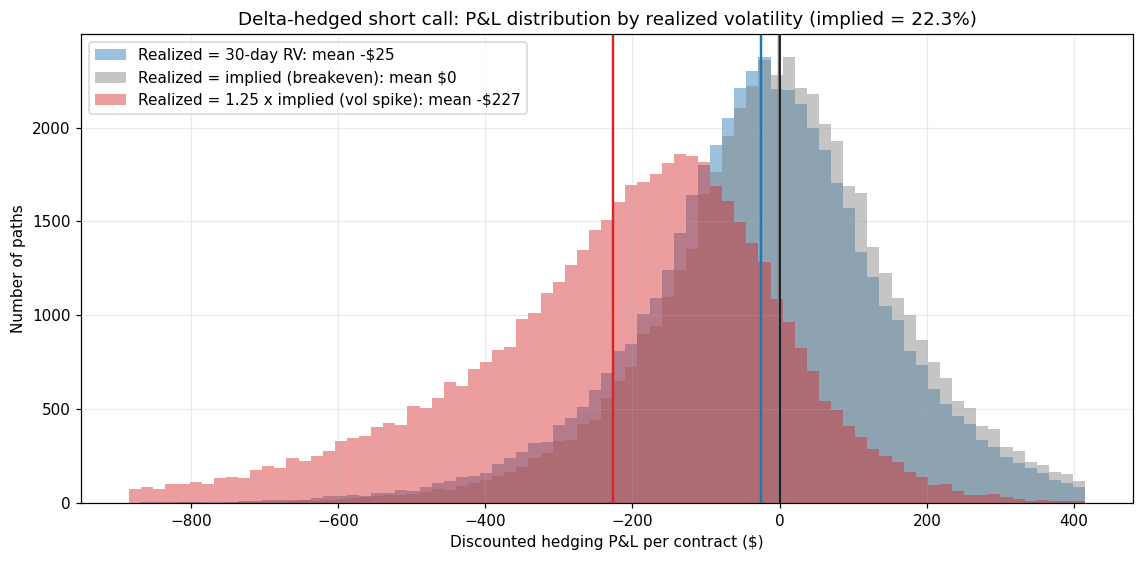

In [55]:
n_hedges = max(int(round(T_mkt * 252)), 1)        # one hedge per trading day until expiry
N_PATHS = 50_000
vega_100 = bs_greeks(S_mkt, k_atm, T_mkt, r_mkt, atm_iv, q_mkt)["vega"] * 100   # $ per contract per 1.00 of vol

scenarios = [("Realized = 30-day RV", rv_30, "tab:blue"),
             ("Realized = implied (breakeven)", atm_iv, "tab:gray"),
             ("Realized = 1.25 x implied (vol spike)", 1.25 * atm_iv, "tab:red")]

hedge_results, hedge_rows = {}, []
for name, sig_r, _ in scenarios:
    p_ = delta_hedge_pnl(S_mkt, k_atm, T_mkt, r_mkt, atm_iv, sig_r, q_mkt,
                         n_steps=n_hedges, n_paths=N_PATHS, seed=42) * 100
    hedge_results[name] = p_
    hedge_rows.append({"Scenario": name, "Realized vol": sig_r, "Mean P&L ($)": p_.mean(),
                       "Std dev ($)": p_.std(), "5th percentile ($)": np.percentile(p_, 5),
                       "P(loss)": np.mean(p_ < 0), "Vega x (IV - RV) ($)": vega_100 * (atm_iv - sig_r)})
hedge_tbl = pd.DataFrame(hedge_rows)

print(f"Short 1 {TICKER} {expiry} {k_atm:g} call at {atm_iv:.1%} implied vol, hedged {n_hedges} times "
      f"({N_PATHS:,} paths)")
print(f"Premium collected: ${bs_price(S_mkt, k_atm, T_mkt, r_mkt, atm_iv, q_mkt) * 100:,.2f} per contract   "
      f"|   Vega: ${vega_100 / 100:,.2f} per vol point")
display(hedge_tbl.style.format({"Realized vol": "{:.1%}", "Mean P&L ($)": "{:,.0f}", "Std dev ($)": "{:,.0f}",
                                "5th percentile ($)": "{:,.0f}", "P(loss)": "{:.0%}",
                                "Vega x (IV - RV) ($)": "{:,.0f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(10.5, 5.2))
allp = np.concatenate(list(hedge_results.values()))
bins = np.linspace(*np.percentile(allp, [0.5, 99.5]), 80)
for name, sig_r, col in scenarios:
    p_ = hedge_results[name]
    ax.hist(p_, bins=bins, alpha=0.45, color=col, label=f"{name}: mean {'-' if round(p_.mean()) < 0 else ''}${abs(round(p_.mean())):,.0f}")
    ax.axvline(p_.mean(), color=col, linewidth=1.6)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Discounted hedging P&L per contract ($)")
ax.set_ylabel("Number of paths")
ax.set_title(f"Delta-hedged short call: P&L distribution by realized volatility (implied = {atm_iv:.1%})")
ax.legend()
plt.tight_layout()
plt.show()

### 9.2 Two sweeps: realized volatility and hedging frequency
- **Left:** the mean P&L (line) and a one-standard-deviation band as realized volatility varies from half to one-and-a-half times implied. The dashed line is the vega rule of thumb. The P&L crosses zero where realized volatility equals implied volatility. Moving right, the seller's average P&L turns negative and the band widens: losses come with more uncertainty.
- **Right:** the standard deviation of P&L when realized equals implied (so the *average* is zero and only **hedging error** remains), against the number of rebalances. The error shrinks like $1/\sqrt{N}$, so halving it takes four times as many hedges. In practice each hedge costs a bid-ask spread and commissions, so more hedging is not free. This simulation leaves those costs out.

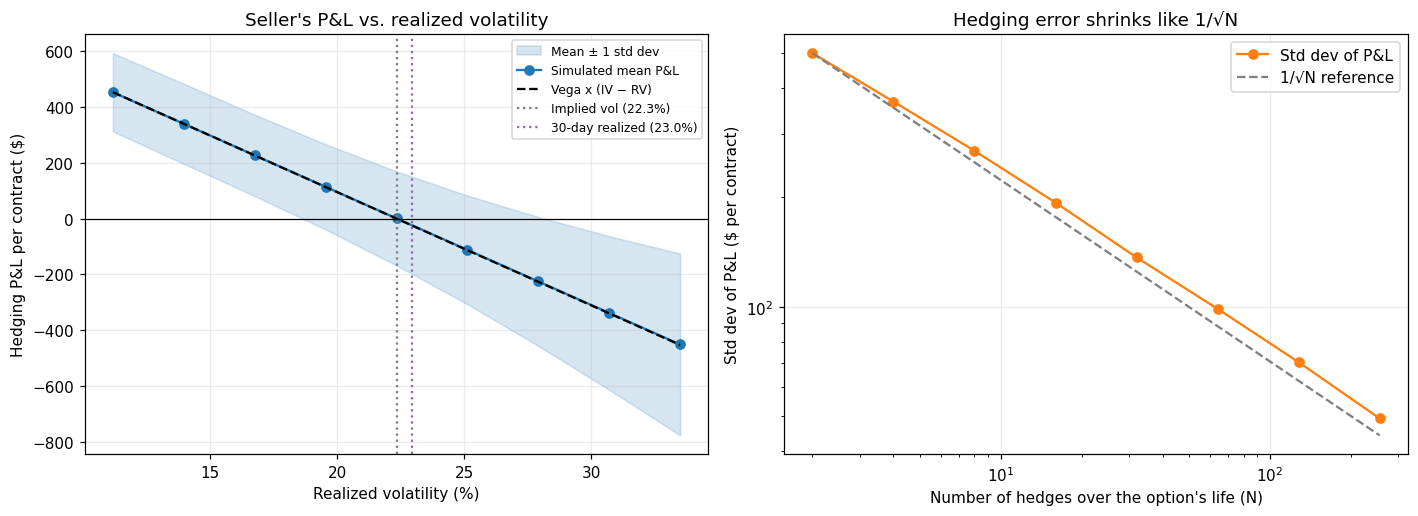

In [56]:
real_grid = np.linspace(0.5 * atm_iv, 1.5 * atm_iv, 9)
sweep = [delta_hedge_pnl(S_mkt, k_atm, T_mkt, r_mkt, atm_iv, s_, q_mkt,
                         n_steps=n_hedges, n_paths=20_000, seed=7) * 100 for s_ in real_grid]
sw_mean = np.array([p_.mean() for p_ in sweep])
sw_sd = np.array([p_.std() for p_ in sweep])

hedge_grid = np.array([2, 4, 8, 16, 32, 64, 128, 256])
hedge_sd = np.array([delta_hedge_pnl(S_mkt, k_atm, T_mkt, r_mkt, atm_iv, atm_iv, q_mkt,
                                     n_steps=m_, n_paths=20_000, seed=7).std() * 100 for m_ in hedge_grid])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
ax.fill_between(real_grid * 100, sw_mean - sw_sd, sw_mean + sw_sd, color="tab:blue", alpha=0.18,
                label="Mean ± 1 std dev")
ax.plot(real_grid * 100, sw_mean, "o-", color="tab:blue", label="Simulated mean P&L")
ax.plot(real_grid * 100, vega_100 * (atm_iv - real_grid), "--", color="black", label="Vega x (IV − RV)")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(atm_iv * 100, color="gray", linestyle=":", label=f"Implied vol ({atm_iv:.1%})")
ax.axvline(rv_30 * 100, color="tab:purple", linestyle=":", label=f"30-day realized ({rv_30:.1%})")
ax.set_xlabel("Realized volatility (%)")
ax.set_ylabel("Hedging P&L per contract ($)")
ax.set_title("Seller's P&L vs. realized volatility")
ax.legend(fontsize=8)

ax = axes[1]
ax.loglog(hedge_grid, hedge_sd, "o-", color="tab:orange", label="Std dev of P&L")
ax.loglog(hedge_grid, hedge_sd[0] * np.sqrt(hedge_grid[0] / hedge_grid), "--", color="gray",
          label="1/√N reference")
ax.set_xlabel("Number of hedges over the option's life (N)")
ax.set_ylabel("Std dev of P&L ($ per contract)")
ax.set_title("Hedging error shrinks like 1/√N")
ax.legend()

plt.tight_layout()
plt.show()

### Reading the results
- **The average tracks the volatility gap.** The simulated mean P&L sits close to vega × (IV − RV) and is about zero when realized volatility equals implied. This is the volatility risk premium measured in dollars: a seller who hedges well earns the implied-minus-realized gap *on average*.
- **The average hides the risk.** Even in the breakeven case the P&L is spread out, and the vol-spike scenario shows how the seller loses when the stock moves more than the option priced in. Short-volatility positions look steady until a large move arrives, which is why the premium is better read as compensation for risk than as free money.
- **Hedging more often reduces noise but not the bias.** More frequent rebalancing shrinks the spread around the mean, but the mean itself is set by the volatility gap alone.
- **Caveats.** The simulation uses constant volatility, no jumps, no transaction costs, and perfect fills. It also compares the option's implied volatility with a *single assumed* future realized volatility, while the true one is unknown until expiry.

## 10. Discussion & limitations

**What worked**
- All three methods agree: the tree converges to Black-Scholes and Monte Carlo falls within its confidence interval, so each implementation validates the others.
- Put-call parity and finite-difference Greek checks confirm the analytic formulas are correct.
- Each method has a clear niche: Black-Scholes for speed, the tree for early exercise, Monte Carlo for path dependence. The runtime and accuracy table quantifies the trade-off.
- Applied to a live option chain, the engine backs out implied volatilities with Brent's method and reproduces the smile. Implied volatility varies with strike, which a single flat $\sigma$ cannot capture, so model error against market prices grows toward the wings.
- The model is useful beyond pricing: it yields an expected move, implied-vs-realized volatility, per-contract Greeks, and P&L scenarios.
- The delta-hedging simulation turns the implied-vs-realized gap into dollars: the hedged seller's average P&L tracks vega × (IV − RV), and hedging error falls like $1/\sqrt{N}$ in the number of rebalances.

**Limitations**
- **Constant volatility.** Black-Scholes, the tree, and the Monte Carlo all assume one $\sigma$. The smile in Section 8 shows this is a simplification, and volatility is the one input that cannot be observed directly.
- **Market data quality.** `yfinance` is free and delayed about 15 minutes. Quotes can be stale, wide, or missing outside market hours, and filtering choices (OTM only, ±15% of spot, spread cap) affect the results.
- **American vs. European.** US equity options are American. Black-Scholes implied volatility treats them as European, a good approximation for OTM options but biased for in-the-money options and dividend payers.
- **Rate and dividend proxies.** The risk-free rate is the 13-week T-bill yield and dividends are a trailing 12-month yield. Real dividends are discrete and rates vary across the curve.
- **Realized volatility is backward-looking** and depends on the window chosen (30 days here).
- **GBM assumptions.** No jumps and no stochastic volatility, so tail risk is underpriced.
- **Binomial oscillation and Monte Carlo cost.** Tree prices oscillate as steps change, and Monte Carlo error shrinks only as $1/\sqrt{N}$.
- **Hedging simulation.** It assumes GBM at one constant realized volatility, no transaction costs, and perfect fills. Real hedging faces jumps, volatility that changes during the option's life, and costs that rise with hedging frequency.
- **No trading implication.** Model-vs-market differences are a diagnostic, not a strategy: they ignore transaction costs, bid-ask spreads, and hedging risk.

**Possible extensions**
- Build a **volatility surface** across multiple expiries (e.g., SVI parameterization) and compare against a **local volatility** model.
- Use a **control variate** (e.g., the closed-form geometric Asian) to cut Monte Carlo variance on the Asian option.
- Price American options with Monte Carlo using **Longstaff-Schwartz** and validate against the tree.
- Extend to **Heston** stochastic volatility and calibrate it to the live chain.
- Extend the hedging study with **transaction costs** (and hedge-band rules), and rerun it with jump or stochastic-volatility paths.
- Rewrite the Monte Carlo core in **C++** and compare runtime.